# Mixed Scheduling for Long-Input Serving

[中文](../../docs/zh-CN/reports/long_input_serving/mixed_scheduling_report.ipynb)
## Two arrival seeds and three execution blocks

**Finding: mixed reduces long stalls after generation starts and shortens completion latency. It also improves throughput at high load, at the cost of a longer wait for the first token.**

This report uses only the completed serving experiments; no new inference experiments are run. The primary baseline is **separate**, with interleaved as a secondary comparison. The Python cells below recompute all results from the complete published measurement JSON files. Figures are generated with Matplotlib.

> **Evidence boundary:** This is a synthetic Poisson-arrival experiment using the same set of complete SPEED-Bench long texts, not a replay of production traffic. All configurations have cross-policy output-hash mismatches, so these observations do not establish equivalent answers or superiority across all metrics.

Reading order: data audit → overall tradeoff → paired benefits → generation stalls → latency decomposition and backlog → conclusion limits.

## 1. Data and reproduction

Data directory: `reports/data/long_input_serving/formal`.

Executed outputs are embedded for immediate reading. To rerun, use the repository's `.venv` Python kernel with `numpy`, `matplotlib`, and `IPython`. The code searches parent directories for the repository root and does not depend on machine-specific absolute paths. It reads results and writes figures without loading a model.

The statistical unit is one complete replay. Each rate × arrival seed × budget × policy has three blocks; the 100 requests are not treated as 100 independent experiments.

Published data retains all request measurements and policy summaries. Input-token sequences are represented only by lengths and SHA-256 hashes; the duplicate top-level summary is removed. These records support performance reanalysis, not direct inference replay. See the [data documentation](../data/README.md) for export rules and original-file fingerprints.

In [1]:
%matplotlib inline
import json, math, statistics as st, itertools, hashlib
from pathlib import Path
from collections import defaultdict, Counter
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'reports/data/long_input_serving/formal').is_dir())
FORMAL = ROOT / 'reports/data/long_input_serving/formal'
FIGURES = ROOT / 'reports/long_input_serving/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.sans-serif'] = [f for f in ['DejaVu Sans'] if f in fonts]
plt.rcParams.update({'axes.unicode_minus': False, 'figure.dpi': 120,
                     'savefig.dpi': 170, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
COLORS = {'separate': '#64748b', 'interleaved': '#d59627', 'mixed': '#087f8c'}
POLICIES = ['separate', 'interleaved', 'mixed']
BLOCKS = [0, 3, 4]
RATES = [0.5, 0.75, 1.0]
SEEDS = [20261012, 20261013]
def read(p): return json.loads(p.read_text(encoding='utf-8-sig'))
def table(headers, body):
    display(Markdown('| ' + ' | '.join(headers) + ' |\n| ' + ' | '.join(['---']*len(headers)) + ' |\n' +
                     '\n'.join('| ' + ' | '.join(map(str, r)) + ' |' for r in body)))
def finish(fig, name):
    fig.savefig(FIGURES / (name + '.png'), bbox_inches='tight')
    plt.show()

In [2]:
schedule = read(FORMAL / 'schedule.json')
assert schedule['block_ids'] == BLOCKS
assert read(FORMAL / 'blocks.json')['entries'] == schedule['entries']
expected_cases = {(rate, seed, budget) for rate in RATES for seed in SEEDS for budget in [384, 512]}
rows, identities, traces, text_sets, hashes = [], defaultdict(set), {}, set(), []
raw = {}
for entry in schedule['entries']:
    case = Path(entry['config']).stem
    path = FORMAL / f"block{entry['block']}" / case / 'results.json'
    d = read(path)
    assert d['status'] == 'complete'
    assert d['settings']['warmup'] == d['settings']['rounds'] == 1
    assert d['settings']['token_budget'] == entry['token_budget']
    assert tuple(r['policy'] for r in d['runs']) == list(itertools.permutations(POLICIES))[entry['block']]
    for k in ['source_sha256', 'environment', 'checkpoint_files']:
        identities[k].add(json.dumps(d[k], sort_keys=True))
    trace = d['trace']; generation = trace['generation']
    rate, seed, budget = generation['arrival_rate'], generation['seed'], entry['token_budget']
    key = (rate, seed)
    if key in traces: assert trace == traces[key]
    traces[key] = trace
    text_sets.add(json.dumps([{k:v for k,v in q.items() if k != 'arrival_s'} for q in trace['requests']], sort_keys=True))
    specs = {q['id']: q for q in trace['requests']}
    assert len(specs) == len(trace['requests']) == 100
    hashes.append(d['matching_outputs'])
    for run in d['runs']:
        requests = sorted(run['requests'], key=lambda q:q['arrival_s'])
        assert len(requests) == len({q['id'] for q in requests}) == 100
        assert {q['id'] for q in requests} == set(specs)
        for q in requests:
            assert q['output_tokens'] == specs[q['id']]['max_tokens'] == 128
            assert q['arrival_s'] == specs[q['id']]['arrival_s']
            assert q['arrival_s'] <= q['admission_s'] <= q['first_token_s'] <= q['last_token_s']
            assert math.isclose(q['e2e_ms'], q['ttft_ms'] + 127*q['tpot_ms'], abs_tol=1e-6)
        s = run['summary']; g = run['online']['groups']['all']
        assert math.isclose(s['elapsed_s']*s['output_tok_s'], 12800, abs_tol=1e-6)
        for m in ['ttft_ms', 'e2e_ms', 'tpot_ms']:
            assert math.isclose(st.mean(q[m] for q in requests), s[m]['mean'], abs_tol=1e-6)
        row = dict(rate=rate, seed=seed, budget=budget, block=entry['block'], policy=run['policy'],
                   case=case, source=str(path.relative_to(FORMAL)),
                   throughput=s['output_tok_s'], ttft=s['ttft_ms']['mean']/1000,
                   e2e=s['e2e_ms']['mean']/1000, e2e95=s['e2e_ms']['p95']/1000,
                   decode=127*s['tpot_ms']['mean']/1000, itl95=s['itl_ms']['p95'],
                   stall95=g['max_itl_ms']['p95'], preemptions=s['counts']['preemptions'],
                   mixed_fraction=s['mixed_step_fraction'], steps=s['counts']['steps'],
                   drain=max(q['last_token_s'] for q in requests)-max(q['arrival_s'] for q in requests))
        assert all(math.isfinite(row[m]) for m in ['throughput','ttft','e2e','e2e95','decode','itl95','stall95','drain'])
        rows.append(row)
        raw[rate,seed,budget,entry['block'],run['policy']] = requests
index = {(r['rate'],r['seed'],r['budget'],r['block'],r['policy']):r for r in rows}
assert len(index) == len(rows) == 108
assert set(index) == {(rate,seed,budget,b,p) for rate,seed,budget in expected_cases for b in BLOCKS for p in POLICIES}
assert all(len(v)==1 for v in identities.values()) and len(text_sets)==1
lengths = [q['input_tokens'] for q in trace['requests']]
env = d['environment']
table(['Audit item','Result'], [
    ['Complete files / formal replays / request records', f"{len(hashes)} / {len(rows)} / {sum(len(v) for v in raw.values())}"],
    ['Arrival seeds / blocks', f'{SEEDS} / {BLOCKS}'],
    ['Rates / token budgets', f'{RATES} req/s / 384, 512'],
    ['Independent text sets / input lengths', f'{len(text_sets)} / {min(lengths)}–{max(lengths)} token'],
    ['Text categories', str(dict(Counter(q['category'] for q in trace['provenance'])))],
    ['Model / GPU / dtype', f"{d['settings']['model']} / {env['gpu']} / {d['settings']['dtype']}"],
    ['Max sequences per batch / KV blocks / prefix cache', f"{d['settings']['max_seqs']} / {d['settings']['blocks']} / {d['settings']['prefix_cache']}"],
    ['Distinct source / environment / model fingerprints', str({k:len(v) for k,v in identities.items()})],
    ['Files with cross-policy output-hash mismatches', f'{sum(not v for v in hashes)} / {len(hashes)}'],
    ['Duplicates, missing combinations, nonfinite metrics, numerical identities', 'All checks passed; no outliers removed']])
def values(rate, seed, budget, policy, metric):
    return np.array([index[rate,seed,budget,b,policy][metric] for b in BLOCKS])
def mean(rate, seed, budget, policy, metric):
    return float(values(rate,seed,budget,policy,metric).mean())
def change(rate, seed, budget, metric, baseline='separate'):
    a=mean(rate,seed,budget,baseline,metric); b=mean(rate,seed,budget,'mixed',metric)
    return 100*(b/a-1)

| Audit item | Result |
| --- | --- |
| Complete files / formal replays / request records | 36 / 108 / 10800 |
| Arrival seeds / blocks | [20261012, 20261013] / [0, 3, 4] |
| Rates / token budgets | [0.5, 0.75, 1.0] req/s / 384, 512 |
| Independent text sets / input lengths | 1 / 1941–2171 token |
| Text categories | {'high_entropy': 50, 'low_entropy': 50} |
| Model / GPU / dtype | /root/model/Qwen3-4B / NVIDIA GeForce RTX 4090 / bfloat16 |
| Max sequences per batch / KV blocks / prefix cache | 16 / 565 / False |
| Distinct source / environment / model fingerprints | {'source_sha256': 1, 'environment': 1, 'checkpoint_files': 1} |
| Files with cross-policy output-hash mismatches | 36 / 36 |
| Duplicates, missing combinations, nonfinite metrics, numerical identities | All checks passed; no outliers removed |

## 2. Throughput, completion latency, and first-token tradeoffs

Each line represents one policy. Solid lines use seed 20261012, dashed lines seed 20261013; points are three-block means. Seeds are shown separately so arrival-stream differences remain visible.

**What to look for:** At low arrival rates, throughput is similar even when completion latency improves. At high load, mixed improves throughput but also increases first-token waits. Throughput here includes arrival waits and final draining; it is not maximum steady-state capacity.

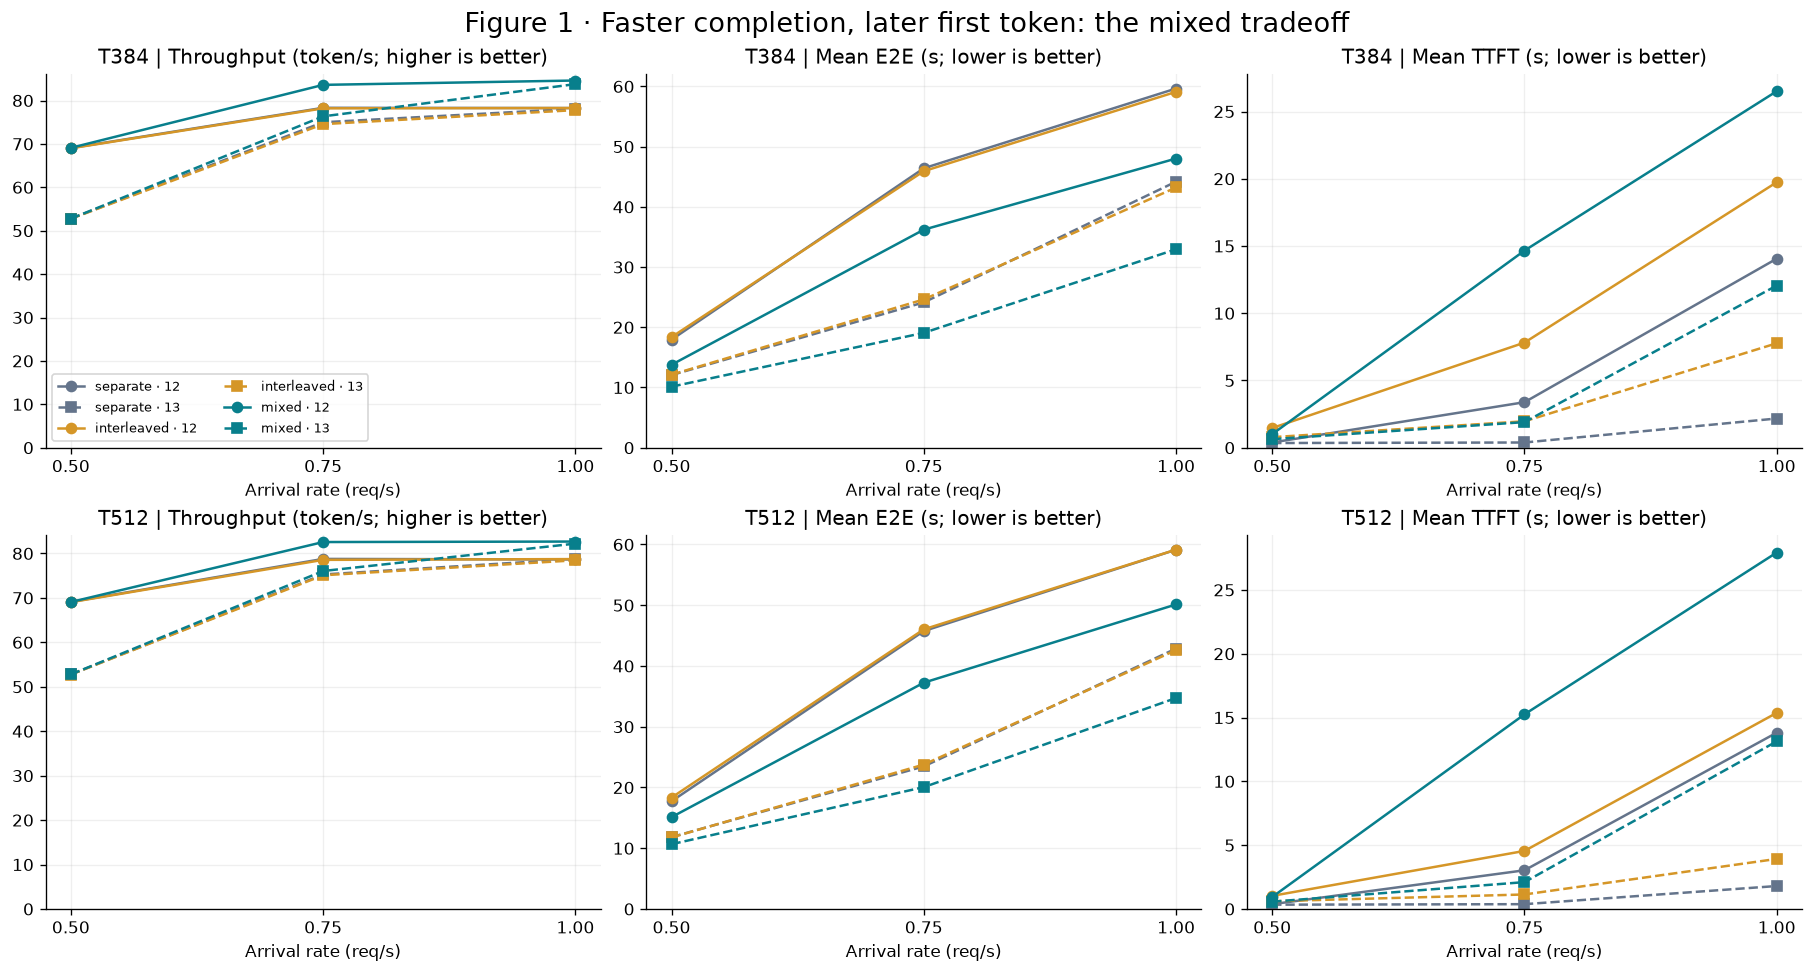

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
for i,budget in enumerate([384,512]):
    for j,(metric,label) in enumerate([('throughput','Throughput (token/s; higher is better)'),('e2e','Mean E2E (s; lower is better)'),('ttft','Mean TTFT (s; lower is better)')]):
        ax=axes[i,j]
        for policy in POLICIES:
            for seed,ls,marker in [(SEEDS[0],'-','o'),(SEEDS[1],'--','s')]:
                ax.plot(RATES,[mean(rate,seed,budget,policy,metric) for rate in RATES],color=COLORS[policy],linestyle=ls,marker=marker,label=f'{policy} · {str(seed)[-2:]}')
        ax.set(title=f'T{budget} | {label}',xlabel='Arrival rate (req/s)',xticks=RATES)
        ax.grid(alpha=.2); ax.set_ylim(bottom=0)
axes[0,0].legend(fontsize=8,ncol=2)
fig.suptitle('Figure 1 · Faster completion, later first token: the mixed tradeoff', fontsize=16)
finish(fig,'01_tradeoff')

## 3. Paired benefits across all configurations

The figure uses a common convention: positive means better. Throughput uses `(mixed / separate − 1) × 100%`; latency uses `(1 − mixed / separate) × 100%`. Each ratio is calculated after averaging the three blocks, without mixing configurations.

Colors are clipped at ±100%; **cell labels retain the actual percentages**. Large negative TTFT values represent costs and must not be ignored.

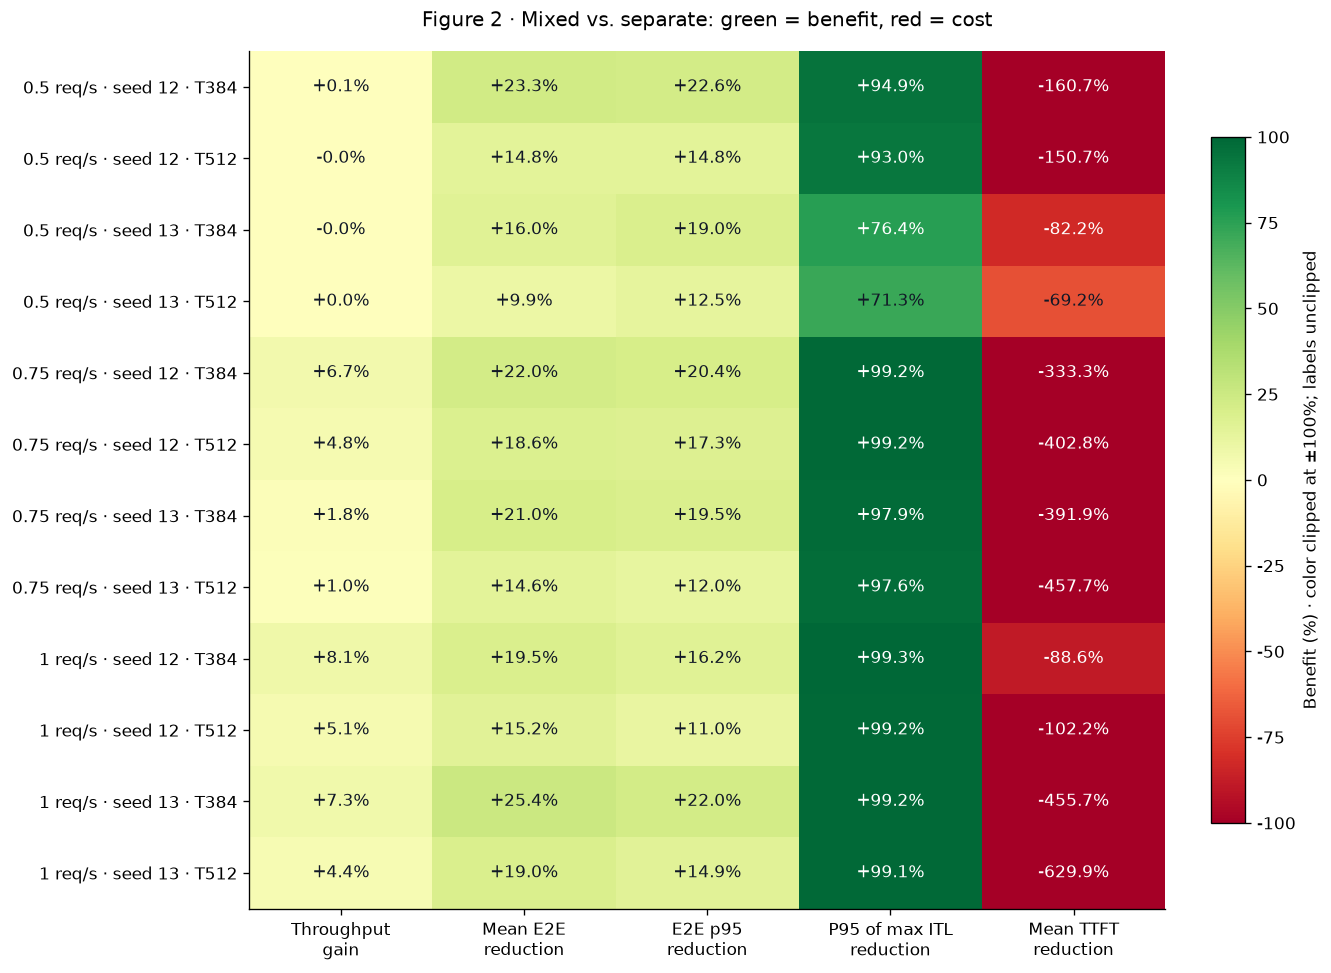

| Metric | Pairs favoring mixed | Configurations with a favorable paired 95% t interval |
| --- | --- | --- |
| throughput | 30/36 | 9/12 |
| e2e | 36/36 | 12/12 |
| e2e95 | 36/36 | 12/12 |
| stall95 | 36/36 | 12/12 |
| ttft | 0/36 | 0/12 |

In [4]:
cases=sorted(expected_cases)
metrics=['throughput','e2e','e2e95','stall95','ttft']
benefit=np.array([[change(*c,m)*(1 if m=='throughput' else -1) for m in metrics] for c in cases])
fig,ax=plt.subplots(figsize=(11,8),layout='constrained')
im=ax.imshow(benefit,cmap='RdYlGn',vmin=-100,vmax=100,aspect='auto')
ax.set_xticks(range(5),['Throughput\ngain','Mean E2E\nreduction','E2E p95\nreduction','P95 of max ITL\nreduction','Mean TTFT\nreduction'])
ax.set_yticks(range(len(cases)),[f'{rate:g} req/s · seed {str(seed)[-2:]} · T{budget}' for rate,seed,budget in cases])
for i in range(len(cases)):
    for j in range(5):
        ax.text(j,i,f'{benefit[i,j]:+.1f}%',ha='center',va='center',color='white' if abs(benefit[i,j])>75 else '#111827',fontsize=10)
ax.set_title('Figure 2 · Mixed vs. separate: green = benefit, red = cost',pad=15)
fig.colorbar(im,ax=ax,label='Benefit (%) · color clipped at ±100%; labels unclipped',shrink=.8)
finish(fig,'02_paired_benefits')

body=[]
for metric in metrics:
    deltas=[index[*c,b,'mixed'][metric]-index[*c,b,'separate'][metric] for c in cases for b in BLOCKS]
    wins=sum(v>0 if metric=='throughput' else v<0 for v in deltas)
    intervals=[]
    for c in cases:
        ds=values(*c,'mixed',metric)-values(*c,'separate',metric)
        half=4.302652729911275*st.stdev(ds)/math.sqrt(3)
        intervals.append((float(ds.mean()-half),float(ds.mean()+half)))
    favorable=sum(lo>0 if metric=='throughput' else hi<0 for lo,hi in intervals)
    body.append([metric,f'{wins}/36',f'{favorable}/12'])
table(['Metric','Pairs favoring mixed','Configurations with a favorable paired 95% t interval'],body)

**Interpretation:** Mean E2E, E2E p95, and the p95 of per-request maximum ITL improve in every pair; mean TTFT worsens in every pair. High-load throughput gains are consistent across blocks, while low-load throughput differences are small.

Intervals use paired differences across three blocks with df=2 and describe execution variability. They are exploratory and unadjusted for multiple comparisons. Repeats under two arrival seeds do not constitute multiple independent text sets.

## 4. Which generation stalls does mixed reduce?

**Token ITL p95** is a percentile over output-token intervals. **P95 of per-request maximum ITL** first finds each request's longest interval, then takes the p95 across 100 requests. The latter emphasizes rare long generation stalls. These metrics are distinct, and neither includes waiting before the first token.

Every formal replay appears below. Each rate × policy includes two seeds and three blocks; no confidence interval is inferred by pooling seeds. The left panels use a logarithmic axis to show both millisecond- and second-scale stalls.

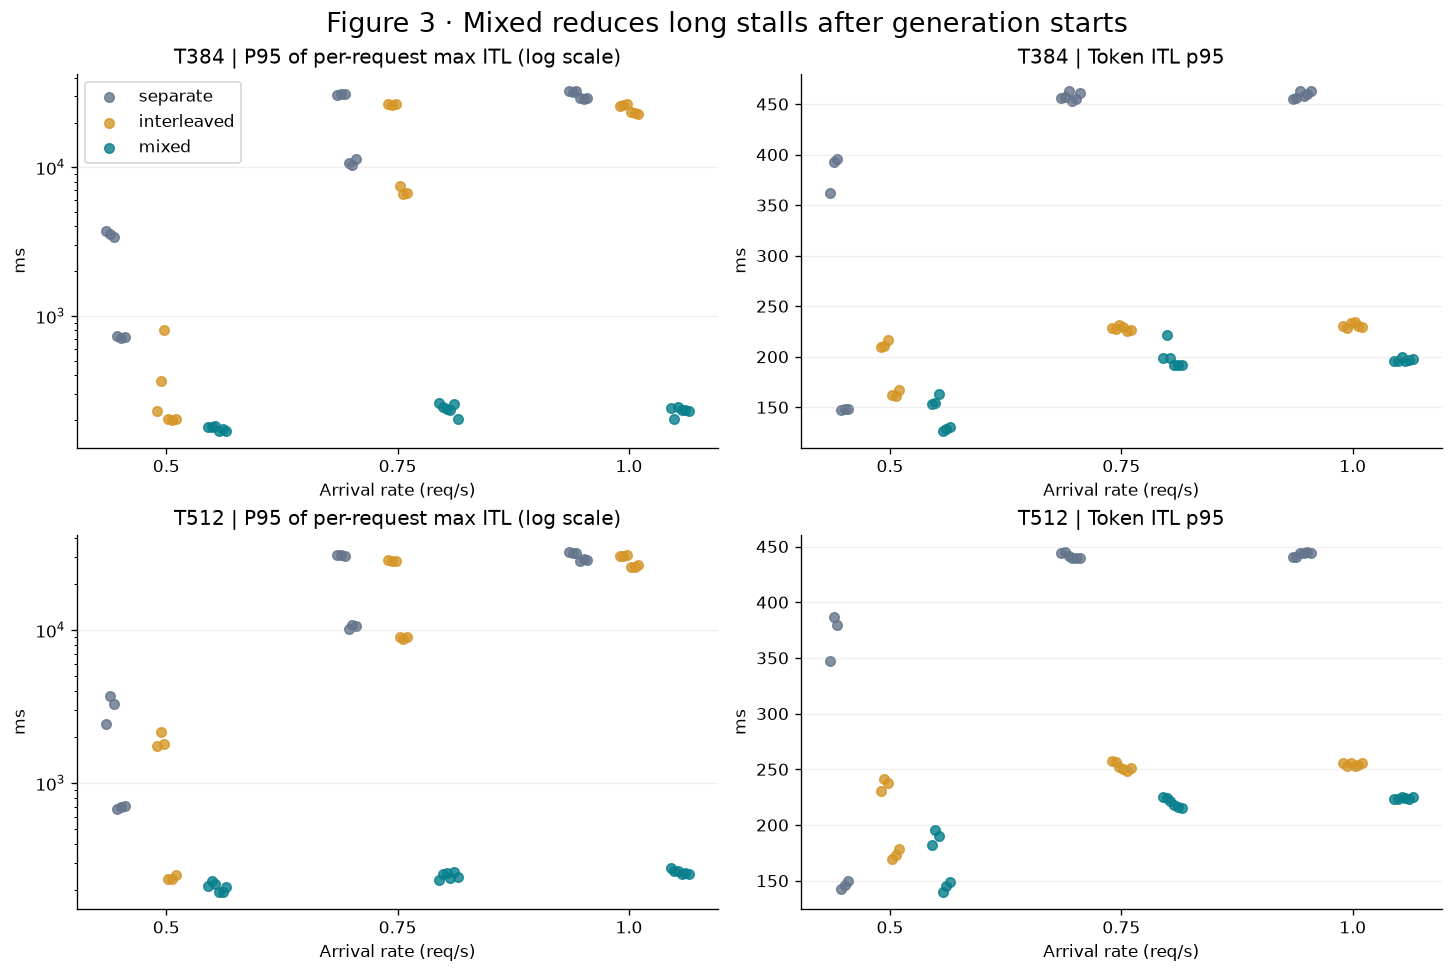

In [5]:
fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
for i,budget in enumerate([384,512]):
    for j,metric in enumerate(['stall95','itl95']):
        ax=axes[i,j]
        for ri,rate in enumerate(RATES):
            for pi,policy in enumerate(POLICIES):
                xs=[];ys=[]
                for si,seed in enumerate(SEEDS):
                    for bi,b in enumerate(BLOCKS):
                        xs.append(ri+(pi-1)*.22+(si*3+bi-2.5)*.016)
                        ys.append(index[rate,seed,budget,b,policy][metric])
                ax.scatter(xs,ys,color=COLORS[policy],s=32,alpha=.8,label=policy if ri==0 else None)
        ax.set_xticks(range(3),RATES);ax.set_xlabel('Arrival rate (req/s)');ax.set_ylabel('ms')
        ax.set_title(f'T{budget} | '+('P95 of per-request max ITL (log scale)' if j==0 else 'Token ITL p95'))
        if j==0: ax.set_yscale('log')
        ax.grid(alpha=.2,axis='y')
axes[0,0].legend()
fig.suptitle('Figure 3 · Mixed reduces long stalls after generation starts',fontsize=16)
finish(fig,'03_generation_stalls')

At high load, separate's p95 of per-request maximum ITL reaches tens of seconds, while mixed stays on the order of hundreds of milliseconds in these replays. This supports more continuous generation, not a claim that overall response time improves by 99%.

Stall reductions also appear in low-load configurations without preemption, so avoiding preemption cannot explain all of the benefit.

## 5. Why does completion improve when the first token arrives later?

With a fixed 128-token output, every request satisfies:

$$\mathrm{E2E}=\mathrm{TTFT}+127\times\mathrm{TPOT}$$

The figure uses the shared high-load configuration `1.0 req/s, T384` and shows both seeds. Each bar is a three-block mean: the lighter segment is TTFT; the darker segment is generation after the first token.

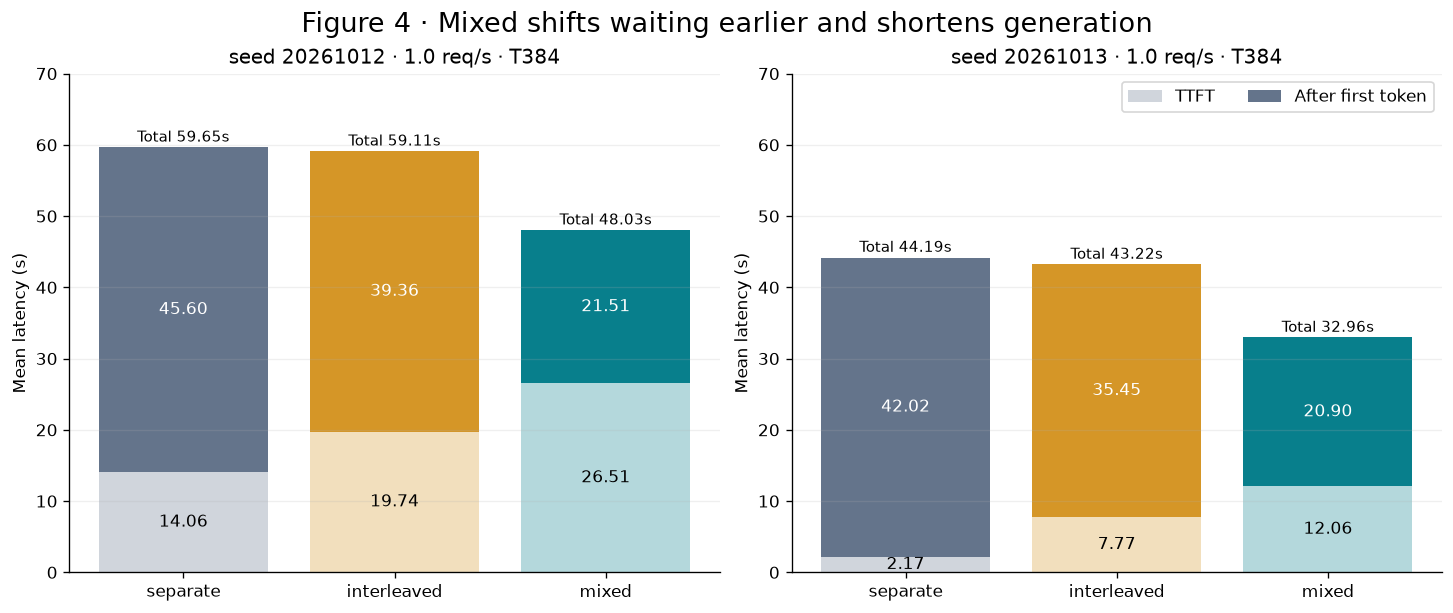

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for ax,seed in zip(axes,SEEDS):
    for i,policy in enumerate(POLICIES):
        first=mean(1.0,seed,384,policy,'ttft'); after=mean(1.0,seed,384,policy,'decode')
        ax.bar(i,first,color=COLORS[policy],alpha=.3,label='TTFT' if i==0 else None)
        ax.bar(i,after,bottom=first,color=COLORS[policy],label='After first token' if i==0 else None)
        ax.text(i,first/2,f'{first:.2f}',ha='center',va='center')
        ax.text(i,first+after/2,f'{after:.2f}',ha='center',va='center',color='white')
        ax.text(i,first+after+.8,f'Total {first+after:.2f}s',ha='center',fontsize=9)
    ax.set(xticks=range(3),xticklabels=POLICIES,ylabel='Mean latency (s)',title=f'seed {seed} · 1.0 req/s · T384',ylim=(0,70))
    ax.grid(axis='y',alpha=.2)
axes[1].legend(loc='upper right', ncol=2)
fig.suptitle('Figure 4 · Mixed shifts waiting earlier and shortens generation',fontsize=16)
finish(fig,'04_latency_decomposition')

For seed 20261012, separate has a mean TTFT of 14.06 s and subsequent generation time of 45.60 s; mixed has 26.51 s and 21.51 s, respectively. Total completion time falls from 59.65 s to 48.03 s.

In the implementation, separate prioritizes prefill. Mixed schedules decode first, then assigns remaining token and batch slots to prefill. This is consistent with protecting generation continuity while delaying new requests' first tokens. Existing data cannot independently quantify the contributions of a shared forward pass, scheduling priority, and resource occupancy.

## 6. Backlog and resource behavior

Request timestamps reconstruct the number of requests that have arrived but not completed. This includes waiting and running requests; **it is not the scheduler's waiting-queue length**.

At `1.0 req/s, T384`, each seed shows the range across three blocks (shading) and their mean (line). Vertical dotted lines mark the last request arrival.

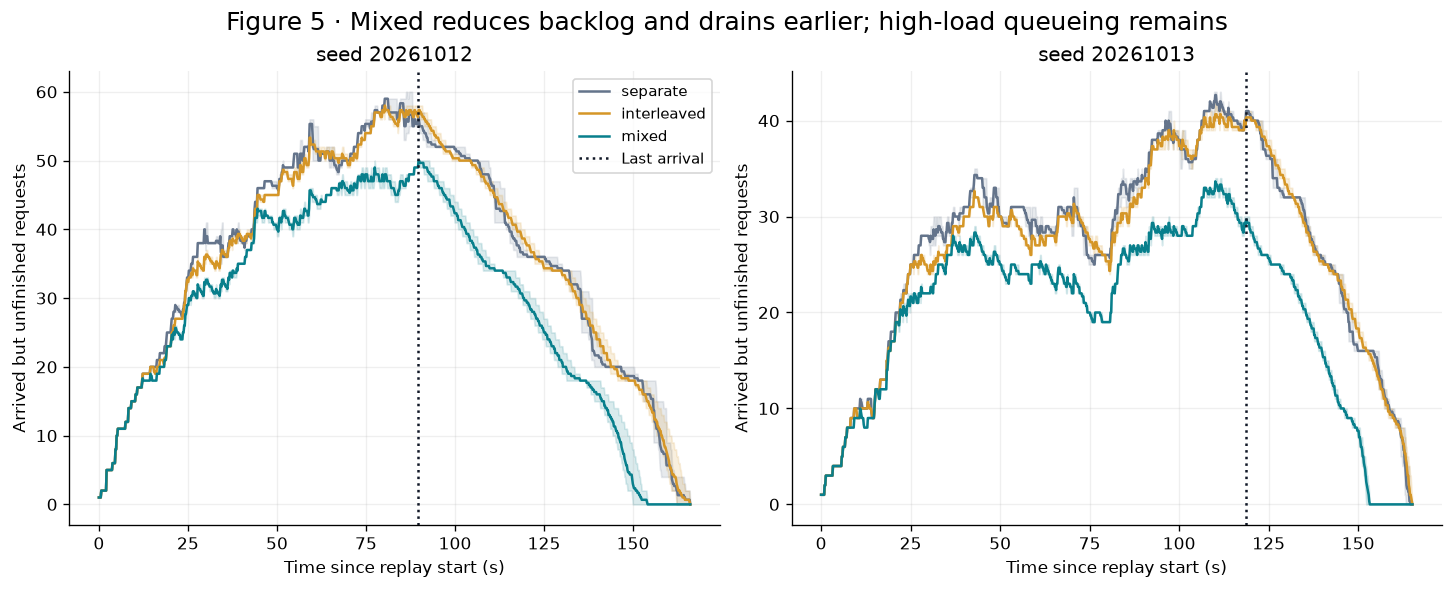

| Policy | Total preemptions across formal replays | Replays with preemptions | Mixed-step fraction range |
| --- | --- | --- | --- |
| separate | 27 | 16 | 0.0%–0.0% |
| interleaved | 8 | 5 | 0.0%–0.0% |
| mixed | 0 | 0 | 11.1%–60.3% |

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout='constrained')
for ax,seed in zip(axes,SEEDS):
    end=max(q['last_token_s'] for p in POLICIES for b in BLOCKS for q in raw[1.0,seed,384,b,p])
    grid=np.linspace(0,end,1000)
    for policy in POLICIES:
        curves=[]
        for b in BLOCKS:
            qs=raw[1.0,seed,384,b,policy]
            curves.append([sum(q['arrival_s']<=t<q['last_token_s'] for q in qs) for t in grid])
        curves=np.array(curves)
        ax.plot(grid,curves.mean(axis=0),color=COLORS[policy],label=policy)
        ax.fill_between(grid,curves.min(axis=0),curves.max(axis=0),color=COLORS[policy],alpha=.15)
    last=max(q['arrival_s'] for q in raw[1.0,seed,384,0,'separate'])
    ax.axvline(last,color='#111827',linestyle=':',label='Last arrival')
    ax.set(title=f'seed {seed}',xlabel='Time since replay start (s)',ylabel='Arrived but unfinished requests')
    ax.grid(alpha=.2)
axes[0].legend(fontsize=9)
fig.suptitle('Figure 5 · Mixed reduces backlog and drains earlier; high-load queueing remains',fontsize=15)
finish(fig,'05_backlog')
table(['Policy','Total preemptions across formal replays','Replays with preemptions','Mixed-step fraction range'],[
    [p,sum(r['preemptions'] for r in rows if r['policy']==p),
     sum(r['preemptions']>0 for r in rows if r['policy']==p),
     f"{min(r['mixed_fraction'] for r in rows if r['policy']==p):.1%}–{max(r['mixed_fraction'] for r in rows if r['policy']==p):.1%}"] for p in POLICIES])

Mixed actually combines prefill and decode work, and has no preemptions in these formal replays. Separate and interleaved do experience preemptions, so high-load differences include scheduling, admission, and recomputation effects. The entire throughput difference cannot be attributed directly to GPU batching efficiency.

In this dataset, mixed/T384 has lower mean E2E than mixed/T512 in all six rate × seed combinations. This makes it a candidate when prioritizing generation continuity under these conditions. It is not a proven globally optimal budget; its TTFT can also be slightly worse at low load.

## 7. Full configuration tables and secondary baseline

The tables retain both seeds and budgets rather than combining them into one score. Each original value is a three-block mean. Arrows indicate separate → mixed. E2E and TTFT are in seconds.

In [8]:
body=[]
for c in cases:
    vals=[]
    for m in ['throughput','e2e','ttft','stall95']:
        vals.append(f"{mean(*c,'separate',m):.2f} → {mean(*c,'mixed',m):.2f}")
    body.append([f'{c[0]:g}/{c[1]}/T{c[2]}',*vals,f"{change(*c,'e2e'):+.2f}%",f"{mean(*c,'mixed','throughput')/mean(*c,'separate','throughput'):.4f}×"])
table(['Rate/seed/budget','Throughput tok/s','E2E s','TTFT s','P95 of per-request max ITL (ms)','E2E change','Throughput ratio'],body)

body=[]
for c in cases:
    body.append([f'{c[0]:g}/{c[1]}/T{c[2]}',*[f"{change(*c,m,baseline='interleaved'):+.2f}%" for m in ['throughput','e2e','ttft']]])
display(Markdown('### Secondary comparison: mixed vs. interleaved (positive means an increase)'))
table(['Rate/seed/budget','Throughput change','Mean E2E change','Mean TTFT change'],body)

| Rate/seed/budget | Throughput tok/s | E2E s | TTFT s | P95 of per-request max ITL (ms) | E2E change | Throughput ratio |
| --- | --- | --- | --- | --- | --- | --- |
| 0.5/20261012/T384 | 69.05 → 69.09 | 17.95 → 13.77 | 0.39 → 1.01 | 3546.22 → 180.38 | -23.26% | 1.0006× |
| 0.5/20261012/T512 | 69.10 → 69.07 | 17.74 → 15.12 | 0.38 → 0.94 | 3138.54 → 219.17 | -14.76% | 0.9996× |
| 0.5/20261013/T384 | 52.79 → 52.78 | 12.06 → 10.14 | 0.35 → 0.63 | 722.62 → 170.89 | -15.96% | 0.9997× |
| 0.5/20261013/T512 | 52.78 → 52.78 | 11.83 → 10.66 | 0.34 → 0.57 | 696.86 → 199.80 | -9.87% | 1.0002× |
| 0.75/20261012/T384 | 78.32 → 83.61 | 46.41 → 36.21 | 3.38 → 14.66 | 30926.98 → 246.11 | -21.97% | 1.0675× |
| 0.75/20261012/T512 | 78.77 → 82.57 | 45.75 → 37.26 | 3.03 → 15.25 | 30778.63 → 247.88 | -18.57% | 1.0482× |
| 0.75/20261013/T384 | 74.99 → 76.35 | 24.14 → 19.08 | 0.39 → 1.90 | 10798.72 → 229.77 | -20.97% | 1.0182× |
| 0.75/20261013/T512 | 75.27 → 76.05 | 23.48 → 20.06 | 0.38 → 2.11 | 10512.34 → 248.46 | -14.55% | 1.0104× |
| 1/20261012/T384 | 78.26 → 84.61 | 59.65 → 48.03 | 14.06 → 26.51 | 32548.71 → 227.58 | -19.50% | 1.0811× |
| 1/20261012/T512 | 78.65 → 82.68 | 59.15 → 50.13 | 13.82 → 27.93 | 32189.78 → 270.37 | -15.24% | 1.0512× |
| 1/20261013/T384 | 78.10 → 83.77 | 44.19 → 32.96 | 2.17 → 12.06 | 29040.05 → 230.99 | -25.40% | 1.0727× |
| 1/20261013/T512 | 78.74 → 82.22 | 42.87 → 34.73 | 1.80 → 13.14 | 28663.22 → 254.87 | -18.99% | 1.0442× |

### Secondary comparison: mixed vs. interleaved (positive means an increase)

| Rate/seed/budget | Throughput change | Mean E2E change | Mean TTFT change |
| --- | --- | --- | --- |
| 0.5/20261012/T384 | +0.15% | -25.03% | -31.02% |
| 0.5/20261012/T512 | +0.05% | -17.55% | -8.49% |
| 0.5/20261013/T384 | +0.04% | -16.40% | -19.18% |
| 0.5/20261013/T512 | +0.07% | -9.48% | -5.84% |
| 0.75/20261012/T384 | +6.92% | -21.15% | +87.57% |
| 0.75/20261012/T512 | +5.10% | -19.07% | +235.13% |
| 0.75/20261013/T384 | +2.41% | -22.55% | -3.10% |
| 0.75/20261013/T512 | +1.28% | -15.64% | +85.09% |
| 1/20261012/T384 | +8.10% | -18.75% | +34.28% |
| 1/20261012/T512 | +5.01% | -15.25% | +81.73% |
| 1/20261013/T384 | +7.69% | -23.73% | +55.29% |
| 1/20261013/T512 | +4.79% | -18.49% | +234.82% |

Relative to interleaved, mixed also improves mean E2E in every pair, but TTFT benefits are not universal: TTFT usually improves at low load and often worsens at high load. This further supports its value for completion speed and generation continuity, rather than improvement in all latency metrics.

## 8. Supported findings and limitations

**Findings supported by the data**

1. In these online replays with approximately 2K-token inputs and fixed 128-token outputs, mixed consistently reduces mean and p95 completion latency and long generation stalls relative to separate.
2. At 1.0 req/s, throughput improves by approximately 4.42%–8.11% across the four seed × budget configurations. At lower rates, throughput is largely unchanged while latency still improves.
3. Benefits come with a consistent TTFT cost. Mixed fits objectives that prioritize generation continuity and total completion time. Suitability for an interactive service depends on its first-token constraints; no SLO was predefined here, so improved SLO goodput is not established.
4. Consistent directions across two seeds and three blocks strengthen repeatability evidence for this workload, without expanding text-set coverage.

**Limitations that must be retained**

- All 36 files have cross-policy output-hash mismatches, and outputs can also differ across blocks within the same policy. Hashes are computed after sorting by request ID, so completion order alone does not explain this. BF16, batch changes, or implementation issues may be involved; current records cannot determine the cause. Fixed output lengths do not establish equivalent output quality.
- One set of 100 texts, fixed output lengths, synthetic Poisson arrivals, one model, and one GPU limit generalization to longer contexts, different output distributions, or production traffic.
- Throughput in a finite replay is not steady-state capacity. TTFT/ITL exclude HTTP and network overhead.
- Full step details and generated tokens were not saved, preventing isolated attribution of GPU batching efficiency or diagnosis of answer equivalence.

> **Conclusion:** These serving experiments demonstrate mixed scheduling's performance role for long-input arrivals: prioritizing requests that have begun generation improves continuity and completion latency, with throughput gains at high load, while delaying new requests' first tokens. This conclusion is limited to the current workload and implementation and does not establish comprehensive superiority with equivalent outputs.

This report explains existing results only; it neither launches nor requires additional experiments.

## Appendix: locating original records

`rate0/1/2` correspond to `0.5/0.75/1.0 req/s`. Each file contains three policies. Cite the file path together with the policy name in `runs`.

In [9]:
table(['Configuration','block','Source record'],[[Path(e['config']).stem,e['block'],
    f"block{e['block']}/{Path(e['config']).stem}/results.json"] for e in schedule['entries']])
print('Figure directory:', FIGURES.relative_to(ROOT).as_posix())
print('Source measurements are read-only; no model or new experiment was run.')

| Configuration | block | Source record |
| --- | --- | --- |
| E_rate0_seed20261012_T384 | 0 | block0/E_rate0_seed20261012_T384/results.json |
| E_rate0_seed20261012_T512 | 0 | block0/E_rate0_seed20261012_T512/results.json |
| E_rate0_seed20261013_T384 | 0 | block0/E_rate0_seed20261013_T384/results.json |
| E_rate0_seed20261013_T512 | 0 | block0/E_rate0_seed20261013_T512/results.json |
| E_rate1_seed20261012_T384 | 0 | block0/E_rate1_seed20261012_T384/results.json |
| E_rate1_seed20261012_T512 | 0 | block0/E_rate1_seed20261012_T512/results.json |
| E_rate1_seed20261013_T384 | 0 | block0/E_rate1_seed20261013_T384/results.json |
| E_rate1_seed20261013_T512 | 0 | block0/E_rate1_seed20261013_T512/results.json |
| E_rate2_seed20261012_T384 | 0 | block0/E_rate2_seed20261012_T384/results.json |
| E_rate2_seed20261012_T512 | 0 | block0/E_rate2_seed20261012_T512/results.json |
| E_rate2_seed20261013_T384 | 0 | block0/E_rate2_seed20261013_T384/results.json |
| E_rate2_seed20261013_T512 | 0 | block0/E_rate2_seed20261013_T512/results.json |
| E_rate0_seed20261013_T512 | 3 | block3/E_rate0_seed20261013_T512/results.json |
| E_rate1_seed20261012_T384 | 3 | block3/E_rate1_seed20261012_T384/results.json |
| E_rate1_seed20261012_T512 | 3 | block3/E_rate1_seed20261012_T512/results.json |
| E_rate1_seed20261013_T384 | 3 | block3/E_rate1_seed20261013_T384/results.json |
| E_rate1_seed20261013_T512 | 3 | block3/E_rate1_seed20261013_T512/results.json |
| E_rate2_seed20261012_T384 | 3 | block3/E_rate2_seed20261012_T384/results.json |
| E_rate2_seed20261012_T512 | 3 | block3/E_rate2_seed20261012_T512/results.json |
| E_rate2_seed20261013_T384 | 3 | block3/E_rate2_seed20261013_T384/results.json |
| E_rate2_seed20261013_T512 | 3 | block3/E_rate2_seed20261013_T512/results.json |
| E_rate0_seed20261012_T384 | 3 | block3/E_rate0_seed20261012_T384/results.json |
| E_rate0_seed20261012_T512 | 3 | block3/E_rate0_seed20261012_T512/results.json |
| E_rate0_seed20261013_T384 | 3 | block3/E_rate0_seed20261013_T384/results.json |
| E_rate1_seed20261012_T384 | 4 | block4/E_rate1_seed20261012_T384/results.json |
| E_rate1_seed20261012_T512 | 4 | block4/E_rate1_seed20261012_T512/results.json |
| E_rate1_seed20261013_T384 | 4 | block4/E_rate1_seed20261013_T384/results.json |
| E_rate1_seed20261013_T512 | 4 | block4/E_rate1_seed20261013_T512/results.json |
| E_rate2_seed20261012_T384 | 4 | block4/E_rate2_seed20261012_T384/results.json |
| E_rate2_seed20261012_T512 | 4 | block4/E_rate2_seed20261012_T512/results.json |
| E_rate2_seed20261013_T384 | 4 | block4/E_rate2_seed20261013_T384/results.json |
| E_rate2_seed20261013_T512 | 4 | block4/E_rate2_seed20261013_T512/results.json |
| E_rate0_seed20261012_T384 | 4 | block4/E_rate0_seed20261012_T384/results.json |
| E_rate0_seed20261012_T512 | 4 | block4/E_rate0_seed20261012_T512/results.json |
| E_rate0_seed20261013_T384 | 4 | block4/E_rate0_seed20261013_T384/results.json |
| E_rate0_seed20261013_T512 | 4 | block4/E_rate0_seed20261013_T512/results.json |

Figure directory: reports/long_input_serving/figures
Source measurements are read-only; no model or new experiment was run.
